# 16 — Neural FL clients: does a sequence model change the federated verdict?

The linear result is settled (11, 14): delta-space FedAvg ≈ pooled, and only small margins over
persistence exist at some specialties. This notebook asks whether a **neural client** — a GRU reading
6 months of (level, momentum, >18w share, >52w share) and predicting the next 1-month *change* — moves
any of that, with weights federated by classic FedAvg, across **every specialty** in the public
`fl_client` pool. Numbered 16 by explicit instruction (15 stays reserved for the post-ratification
agent-rules notebook).

**Everything below is declared a priori (2026-07-30) and nothing is tuned**: one architecture (single
GRU layer, hidden 32, linear head), `SEQ_LEN = 6` (inside the 3–6 months the spec suggests), FedAvg =
10 rounds × 5 local full-batch Adam steps (lr 1e-3), the pooled reference gets the identical total
step budget (50 epochs), seed 42. No sweeps, no early stopping, no validation-based selection of
anything. GPU training is not bit-reproducible (cuDNN), so metrics may wobble in late decimals across
reruns — stated, not hidden. Expected runtime: roughly 10–20 minutes (≈ 46 federated trainings of
~100+ clients each).

**Comparability rule:** a 6-month window needs 6 prior rows, so a few validation rows of the standard
cohorts are ineligible (short histories — the RJ8 case). Every model here — persistence, linear delta
(pooled + FedAvg, 11's exact model recomputed on these rows), neural (pooled + FedAvg) — is scored on
the **identical window-eligible rows**, n beside every score. The 11/14 csv numbers remain the official
anchors on their own denominators. A specialty with zero eligible validation windows is skipped and
named (X01 has no FY 2024-25 rows in this pool — measured in 14).

**Metrics:** MAE and RMSE on levels (comparable to every other notebook), plus **R² on the delta
predictions as an explicitly secondary column** (`r2_delta_secondary`). Level-R² remains rejected —
cross-provider size variance dominates it (the 11 triage) — but delta-R² avoids that artifact and the
spec asks for it. Inputs use declared, statistics-free transforms (`log1p` level, delta/100, raw
shares): no scaling statistic is fitted on anything. Splits, regimes, sealed year: unchanged, asserted.

In [1]:
import numpy as np                           # window arrays, lstsq baselines, arithmetic guards
import pandas as pd                          # panel loading and result tables
import torch                                 # neural clients: a GRU trained per provider, weights federated
from torch import nn                         # layers and the MSE training loss
import copy                                  # deepcopy hands each client its own copy of the global model
from pathlib import Path

PROC = Path("../data/processed")
FIGS = Path("../output/figures"); FIGS.mkdir(parents=True, exist_ok=True)

TEST_START = pd.Timestamp("2025-04-01")      # sealed test year - never read below
VAL_START = pd.Timestamp("2024-04-01")       # validation year FY 2024-25 (unchanged)
COVID = pd.Timestamp("2020-03-01")           # declared regime break (unchanged)

SEED = 42                                    # the project seed; model init and training order flow from it
SEQ_LEN = 6                                  # months of history per window - declared a priori
HIDDEN = 32                                  # GRU hidden units - declared a priori, not tuned
ROUNDS, LOCAL_EPOCHS = 10, 5                 # FedAvg rounds x local full-batch steps per client
POOLED_EPOCHS = ROUNDS * LOCAL_EPOCHS        # pooled reference gets the same total step budget
LR = 1e-3                                    # Adam learning rate - declared a priori, not tuned

torch.manual_seed(SEED)
device = torch.device("cuda")                # CUDA verified on this machine; a missing GPU crashes loudly
panel = pd.read_csv(PROC / "rtt_kh03_canonical_panel.csv", parse_dates=["month"])
dev = panel[(panel["month"] < TEST_START) & panel["fl_client"] & panel["is_public"]]
SPECIALTIES = sorted(dev["tfunc_code"].unique())   # every specialty in the pool - none hand-picked
print(device, "|", len(SPECIALTIES), "specialties,", f"{len(dev):,}", "dev rows in the public fl_client pool")

cuda | 24 specialties, 187,041 dev rows in the public fl_client pool


In [2]:
# Goal: one specialty in -> flat window set out: X (n, 6, 4), scaled delta target, per-row metadata.
def build_windows(df):
    df = df.sort_values(["provider_code", "month"]).copy()
    g = df.groupby("provider_code")["total_waiting"]
    df["target"] = g.shift(-1)               # next month's list
    df["delta_1"] = df["total_waiting"] - g.shift(1)
    df = df.dropna(subset=["target", "delta_1"])       # first row per provider has no momentum yet
    for c in ["pct_gt18", "pct_gt52"]:       # a zero list is 0/0 = NaN in the panel; an empty list
        df[c] = np.where(df["total_waiting"] > 0, df[c], 0.0)   # has no long-waiters, so the share is 0

    X, y, month, prov, current, target, d1 = [], [], [], [], [], [], []
    for p, r in df.groupby("provider_code"):
        f = np.column_stack([np.log1p(r["total_waiting"]), r["delta_1"] / 100,
                             r["pct_gt18"], r["pct_gt52"]]).astype(np.float32)
        t = ((r["target"] - r["total_waiting"]) / 100).to_numpy(np.float32)
        for i in range(SEQ_LEN - 1, len(r)):           # a provider shorter than SEQ_LEN adds nothing -
            X.append(f[i - SEQ_LEN + 1:i + 1]); y.append(t[i])   # the neural cold-start case
        month += list(r["month"].iloc[SEQ_LEN - 1:]); prov += [p] * (len(r) - SEQ_LEN + 1)
        current += list(r["total_waiting"].iloc[SEQ_LEN - 1:])
        target += list(r["target"].iloc[SEQ_LEN - 1:]); d1 += list(r["delta_1"].iloc[SEQ_LEN - 1:])
    return (np.stack(X), np.array(y, dtype=np.float32), pd.Series(month), np.array(prov),
            np.array(current, dtype=float), np.array(target, dtype=float), np.array(d1, dtype=float))

In [3]:
# Goal: the client model and the two training procedures (FedAvg, pooled reference).
class DeltaGRU(nn.Module):                   # one GRU layer reads the 6 months; a linear head -> delta/100
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(4, HIDDEN, batch_first=True)
        self.head = nn.Linear(HIDDEN, 1)
    def forward(self, x):
        out, _ = self.gru(x)
        return self.head(out[:, -1]).squeeze(-1)      # the last month's hidden state carries the sequence

def train_steps(model, X, y, epochs):        # full-batch Adam: client datasets are tiny (<= ~90 windows)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    mse = nn.MSELoss()
    for _ in range(epochs):
        opt.zero_grad(); loss = mse(model(X), y); loss.backward(); opt.step()

def fit_fedavg(client_data):                 # classic FedAvg: broadcast, local steps, weight-average
    glob = DeltaGRU().to(device)
    for _ in range(ROUNDS):
        states, ns = [], []
        for Xc, yc in client_data:
            local = copy.deepcopy(glob)
            train_steps(local, Xc, yc, LOCAL_EPOCHS)
            states.append(local.state_dict()); ns.append(len(yc))
        n_tot = sum(ns)
        glob.load_state_dict({k: sum(sd[k] * n for sd, n in zip(states, ns)) / n_tot
                              for k in states[0]})    # sample-weighted average of every weight tensor
    return glob

def fit_pooled(X, y):                        # centralised reference on the identical total step budget
    model = DeltaGRU().to(device)
    train_steps(model, X, y, POOLED_EPOCHS)
    return model

In [4]:
# Goal: per specialty x regime - persistence, linear delta (pooled + fedavg), neural (pooled + fedavg),
# every model scored on the identical window-eligible validation rows.
def fit_lin(d1_arr, ch_arr):                 # change = a + b * momentum, exact least squares (11's model)
    A = np.column_stack([np.ones(len(d1_arr)), d1_arr])
    beta, *_ = np.linalg.lstsq(A, ch_arr, rcond=None)
    return beta

results, per_client, skipped = [], [], []
for tf in SPECIALTIES:
    X, y, month, prov, current, target, d1 = build_windows(dev[dev["tfunc_code"] == tf])
    assert len(month) == 0 or month.max() < TEST_START
    # the sealed-year sentinel (04/07/08/11/14); the empty branch is a specialty whose providers are
    # all shorter than SEQ_LEN - none expected, but it must not mask the assert
    val = (month >= VAL_START).to_numpy()
    if int(val.sum()) == 0:                  # X01: no FY 2024-25 rows in this pool (measured in 14)
        skipped.append(tf)
        continue
    if tf == "C_110":
        assert 0 < int(val.sum()) < 1407     # eligibility must drop rows (RJ8's short history alone);
                                             # equality would mean the window build is broken
    truth, cur, d1v = target[val], current[val], d1[val]
    dtrue = truth - cur                      # actual validation deltas - the R2 denominator lives here
    ss_tot = ((dtrue - dtrue.mean()) ** 2).sum()
    Xv = torch.tensor(X[val]).to(device)
    def score(pred):                         # MAE + RMSE on levels; R2 on the deltas (secondary)
        err = truth - pred
        r2 = 1 - ((err ** 2).sum() / ss_tot)           # err on levels == err on deltas, same rows
        return float(np.abs(err).mean()), float(np.sqrt((err ** 2).mean())), float(r2)

    mae_n, rmse_n, r2_n = score(cur)
    results.append({"tfunc_code": tf, "regime": "-", "model": "persistence",
                    "mae": mae_n, "rmse": rmse_n, "r2_delta_secondary": r2_n, "n": int(val.sum())})

    for regime, in_reg in [("full", ~val), ("post", ~val & (month >= COVID).to_numpy())]:
        pr = prov[in_reg]
        d1t, cht = d1[in_reg], target[in_reg] - current[in_reg]
        bpool = fit_lin(d1t, cht)
        bd = {p: (fit_lin(d1t[pr == p], cht[pr == p]), int((pr == p).sum())) for p in np.unique(pr)}
        n_tot = sum(n for _, n in bd.values())
        bfed = sum(b * n for b, n in bd.values()) / n_tot
        lin_pool = cur + bpool[0] + bpool[1] * d1v
        lin_fed = cur + bfed[0] + bfed[1] * d1v

        Xt = torch.tensor(X[in_reg]).to(device); yt = torch.tensor(y[in_reg]).to(device)
        cd = [(Xt[pr == p], yt[pr == p]) for p in np.unique(pr)]
        torch.manual_seed(SEED)              # identical init for every model - one declared seed
        npool = fit_pooled(Xt, yt)
        torch.manual_seed(SEED)
        nfed = fit_fedavg(cd)
        with torch.no_grad():                # x100 undoes the declared target scaling
            neu_pool = cur + 100 * npool(Xv).cpu().numpy()
            neu_fed = cur + 100 * nfed(Xv).cpu().numpy()

        for mname, pred in [("linear_pooled", lin_pool), ("linear_fedavg", lin_fed),
                            ("neural_pooled", neu_pool), ("neural_fedavg", neu_fed)]:
            mae, rmse, r2 = score(pred)
            results.append({"tfunc_code": tf, "regime": regime, "model": mname, "mae": mae,
                            "rmse": rmse, "r2_delta_secondary": r2, "n": int(val.sum())})

        if regime == "full":                 # per-client view, full regime (the per-client csv)
            pv = prov[val]
            for p in np.unique(pv):
                m = pv == p
                per_client.append({"tfunc_code": tf, "provider_code": p, "n_val": int(m.sum()),
                                   "mae_naive": float(np.abs(truth[m] - cur[m]).mean()),
                                   "mae_linear_fedavg": float(np.abs(truth[m] - lin_fed[m]).mean()),
                                   "mae_neural_fedavg": float(np.abs(truth[m] - neu_fed[m]).mean())})
    print(f"{tf}: {int(val.sum())} eligible validation windows, {pd.Series(prov[val]).nunique()} clients "
          f"| persistence MAE {mae_n:,.1f} (n={int(val.sum())})")
print("skipped (zero eligible validation windows):", skipped)

C:\Users\heave\Documents\NHS UK FL+Agentic AI\nhs_FL_agentic\Lib\site-packages\torch\nn\modules\rnn.py:1449: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  result = _VF.gru(


C_100: 1300 eligible validation windows, 120 clients | persistence MAE 103.9 (n=1300)


C:\Users\heave\Documents\NHS UK FL+Agentic AI\nhs_FL_agentic\Lib\site-packages\torch\nn\modules\rnn.py:1449: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  result = _VF.gru(


C_101: 1288 eligible validation windows, 118 clients | persistence MAE 100.3 (n=1288)


C:\Users\heave\Documents\NHS UK FL+Agentic AI\nhs_FL_agentic\Lib\site-packages\torch\nn\modules\rnn.py:1449: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  result = _VF.gru(


C_110: 1401 eligible validation windows, 128 clients | persistence MAE 154.1 (n=1401)


... (36 outputs left out)

C:\Users\heave\Documents\NHS UK FL+Agentic AI\nhs_FL_agentic\Lib\site-packages\torch\nn\modules\rnn.py:1449: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  result = _VF.gru(


X05: 1309 eligible validation windows, 119 clients | persistence MAE 119.6 (n=1309)


C:\Users\heave\Documents\NHS UK FL+Agentic AI\nhs_FL_agentic\Lib\site-packages\torch\nn\modules\rnn.py:1449: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1479.)
  result = _VF.gru(


X06: 1326 eligible validation windows, 124 clients | persistence MAE 90.3 (n=1326)
skipped (zero eligible validation windows): ['X01']


In [5]:
# Goal: store both csvs and print the verdict, persistence first in every block.
res = pd.DataFrame(results)
pc = pd.DataFrame(per_client)
res.to_csv(PROC / "fl_neural_summary.csv", index=False)
pc.to_csv(PROC / "fl_neural_per_client.csv", index=False)

wide = res.pivot_table(index="tfunc_code", columns=["model", "regime"], values="mae")
naive = res[res["model"] == "persistence"].set_index("tfunc_code")["mae"]
for regime in ["full", "post"]:
    nf, lf = wide[("neural_fedavg", regime)], wide[("linear_fedavg", regime)]
    print(f"[{regime}] neural fedavg beats linear fedavg at {int((nf < lf).sum())} of {len(nf)} specialties; "
          f"beats persistence at {int((nf < naive).sum())} of {len(nf)}")
    gap = nf - lf
    print(f"[{regime}] neural - linear fedavg MAE gap: median {gap.median():+.2f}, "
          f"best {gap.min():+.2f}, worst {gap.max():+.2f}")

print()
for tf in res["tfunc_code"].unique():
    block = res[res["tfunc_code"] == tf]
    for _, r in block.sort_values(["regime", "mae"]).iterrows():
        print(f"{tf:6s} {r['regime']:5s} {r['model']:15s} MAE {r['mae']:8,.1f}   RMSE {r['rmse']:8,.1f}   "
              f"R2d {r['r2_delta_secondary']:+.3f}   (n={r['n']})")

better = pc["mae_neural_fedavg"] < pc["mae_linear_fedavg"]
print(f"\nneural fedavg beats linear fedavg at {better.mean():.1%} of {len(pc)} "
      f"client-specialty pairs (full regime)")
print(res.shape, "->", PROC / "fl_neural_summary.csv", "|", pc.shape, "->", PROC / "fl_neural_per_client.csv")

[full] neural fedavg beats linear fedavg at 11 of 23 specialties; beats persistence at 11 of 23
[full] neural - linear fedavg MAE gap: median +0.15, best -5.25, worst +3.06
[post] neural fedavg beats linear fedavg at 12 of 23 specialties; beats persistence at 10 of 23
[post] neural - linear fedavg MAE gap: median -0.06, best -5.25, worst +3.06

C_100  -     persistence     MAE    103.9   RMSE    199.5   R2d -0.005   (n=1300)
C_100  full  neural_pooled   MAE    103.1   RMSE    198.4   R2d +0.007   (n=1300)
C_100  full  linear_fedavg   MAE    104.1   RMSE    199.6   R2d -0.006   (n=1300)
C_100  full  neural_fedavg   MAE    104.3   RMSE    199.5   R2d -0.005   (n=1300)
C_100  full  linear_pooled   MAE    106.3   RMSE    200.9   R2d -0.019   (n=1300)
C_100  post  neural_pooled   MAE    104.1   RMSE    198.8   R2d +0.002   (n=1300)
C_100  post  linear_fedavg   MAE    105.2   RMSE    200.3   R2d -0.013   (n=1300)
C_100  post  neural_fedavg   MAE    105.4   RMSE    200.2   R2d -0.011   (n=130

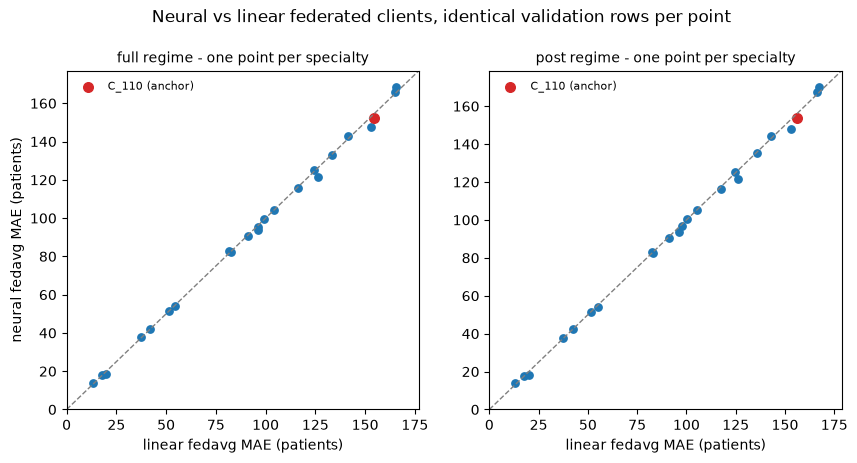

-> ..\output\figures\fl_neural_vs_linear.png


In [6]:
# Goal: the comparison figure - per specialty, neural vs linear FedAvg MAE, one panel per regime.
# Points below the diagonal = neural better. Written to output/figures on explicit instruction
# (13 is otherwise the only output/ writer - deviation recorded in WORKLOG).
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for ax, regime in zip(axes, ["full", "post"]):
    lf, nf = wide[("linear_fedavg", regime)], wide[("neural_fedavg", regime)]
    ax.scatter(lf, nf, color="C0", s=28)
    lim = [0, max(lf.max(), nf.max()) * 1.05]
    ax.plot(lim, lim, color="gray", lw=1, ls="--")   # the diagonal: equal MAE
    c110 = wide.loc["C_110"]
    ax.scatter(c110[("linear_fedavg", regime)], c110[("neural_fedavg", regime)], color="C3", s=48,
               label="C_110 (anchor)")
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel("linear fedavg MAE (patients)")
    ax.set_title(f"{regime} regime - one point per specialty", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("neural fedavg MAE (patients)")
fig.suptitle("Neural vs linear federated clients, identical validation rows per point", y=1.02)
fig.savefig(FIGS / "fl_neural_vs_linear.png", dpi=150, bbox_inches="tight")
plt.show()
print("->", FIGS / "fl_neural_vs_linear.png")